##Student ID:23CE071
#Set:B
#Subject:AIML4001:Responsible and Safe AI

 1. Setup, Package Installation, and Imports

In [42]:
!pip install shap lime -q

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,roc_auc_score
import shap
from lime.lime_tabular import LimeTabularExplainer

2. Load and Preprocess Dataset

In [44]:
url="https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
cols=["checking_status","duration","credit_history","purpose","credit_amount","savings_status","employment","installment_commitment","personal_status","other_parties","residence_since","property_magnitude","age","other_payment_plans","housing","existing_credits","job","num_dependents","own_telephone","foreign_worker","class"]
df=pd.read_csv(url,sep=" ",header=None,names=cols)
df["class"]=df["class"].map({1:0,2:1})
cat_cols=df.select_dtypes(include=["object"]).columns.tolist()
oe=OrdinalEncoder()
df[cat_cols]=oe.fit_transform(df[cat_cols])
x=df.drop(columns=["class"])
y=df["class"]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,stratify=y,random_state=42)



 3. Model Training and Evaluation

In [45]:
rf=RandomForestClassifier(n_estimators=200,max_depth=8,random_state=42)
rf.fit(x_train,y_train)
y_pred=rf.predict(x_test)
y_prob=rf.predict_proba(x_test)[:,1]
acc=accuracy_score(y_test,y_pred)
auc=roc_auc_score(y_test,y_prob)
print(f"Test accuracy : {acc:.2f}      ROC-AUC : {auc:.2f}")

Test accuracy : 0.77      ROC-AUC : 0.81


4. SHAP Global Feature Importance

GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
---------------------------------------
 1    checking_status        0.087
 2    duration               0.041
 3    savings_status         0.039
 4    credit_amount          0.026
 5    credit_history         0.026
---------------------------------------


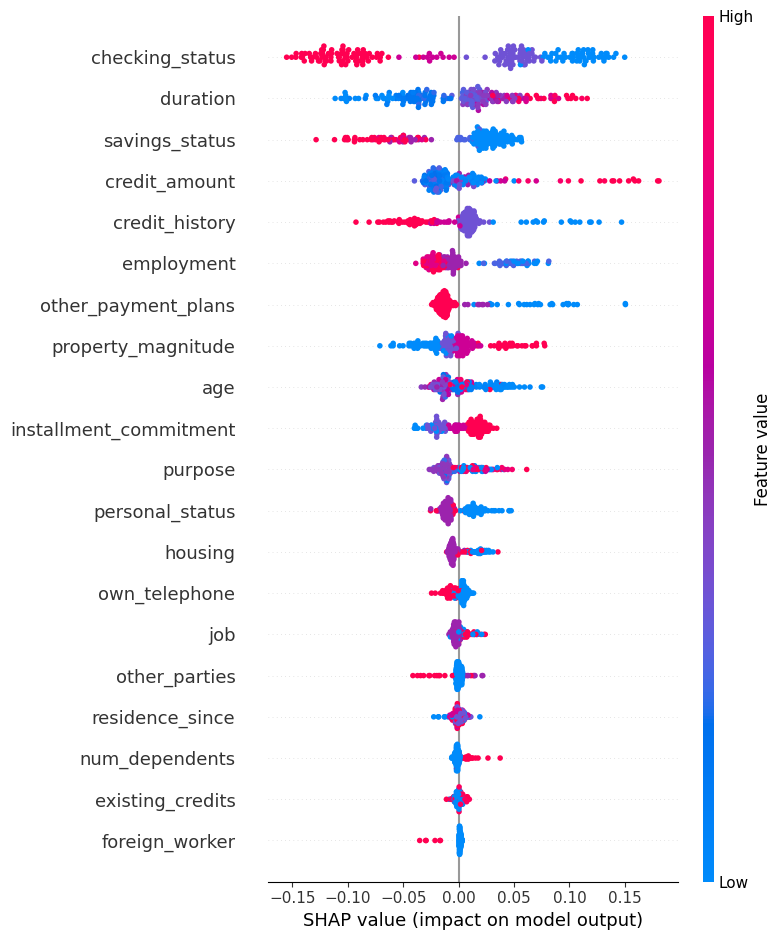

In [46]:
ex=shap.TreeExplainer(rf)
vals=ex(x_test)
shap_val_class1=vals.values[:,:,1] if len(vals.values.shape)==3 else vals.values
mean_shap=np.abs(shap_val_class1).mean(axis=0)
imp_df=pd.DataFrame({"FEATURE":x_test.columns,"MEAN|SHAP|":mean_shap}).sort_values(by="MEAN|SHAP|",ascending=False).reset_index(drop=True)
print("GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print("-"*39)
for idx,row in imp_df.head(5).iterrows():
    print(f"{idx+1:2d}    {row['FEATURE']:20s}   {row['MEAN|SHAP|']:.3f}")
print("-"*39)
plt.figure(figsize=(10,6))
shap.summary_plot(shap_val_class1,x_test,show=False)
plt.tight_layout()
plt.savefig("shap_summary.png")
plt.show()

5. Local Explanations (SHAP vs LIME)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Applicant (test index 23) : P(bad) = 0.61  ->  REJECTED

SHAP Top 3 Positive Contributors to Bad:
checking_status=0.0 : +0.11
duration=24.0 : +0.06
employment=1.0 : +0.05


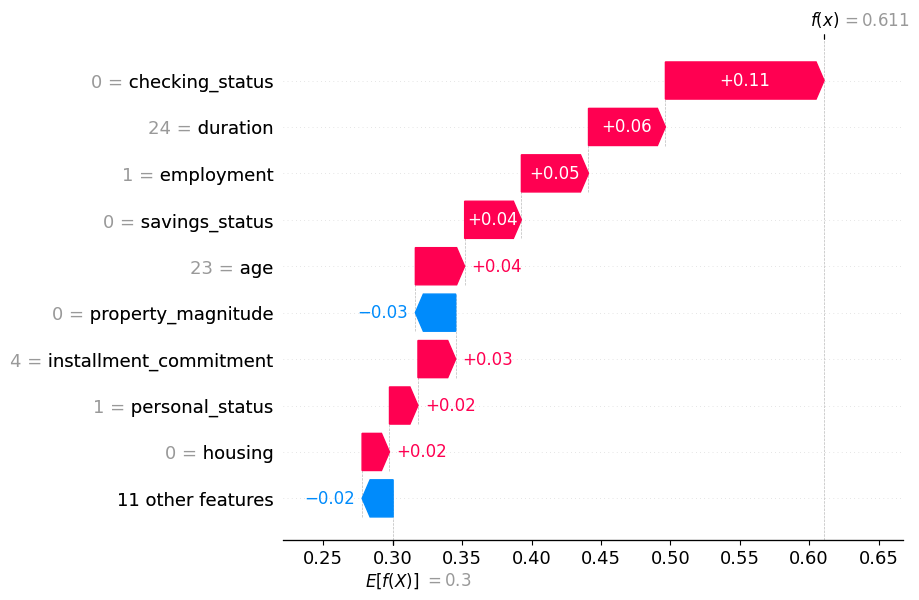

In [47]:
test_idx=23
inst=x_test.iloc[test_idx]
p_bad=rf.predict_proba(inst.values.reshape(1,-1))[0,1]
print(f"Applicant (test index {test_idx}) : P(bad) = {p_bad:.2f}  ->  REJECTED\n")
inst_shap=shap_val_class1[test_idx]
shap_df=pd.DataFrame({"feature":x_test.columns,"val":inst,"shap_val":inst_shap})
shap_df["abs_shap"]=shap_df["shap_val"].abs()
shap_top=shap_df.sort_values(by="shap_val",ascending=False).head(3)
print("SHAP Top 3 Positive Contributors to Bad:")
for idx,row in shap_top.iterrows():
    print(f"{row['feature']}={row['val']} : +{row['shap_val']:.2f}")
plt.figure()
shap.plots.waterfall(shap.Explanation(values=shap_val_class1[test_idx],base_values=ex.expected_value[1],data=inst,feature_names=x_test.columns),show=True)

In [48]:
lm=LimeTabularExplainer(training_data=np.array(x_train),feature_names=x_test.columns.tolist(),class_names=["good","bad"],mode="classification",random_state=42)
exp=lm.explain_instance(data_row=inst,predict_fn=rf.predict_proba,num_features=5)
print("LIME Top 5 Contributors:")
for item in exp.as_list():
    print(f"{item[0]:30s} : {item[1]:+.2f}")

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

LIME Top 5 Contributors:
checking_status <= 0.00        : +0.13
savings_status <= 0.00         : +0.07
credit_history <= 2.00         : +0.07
employment <= 2.00             : +0.05
3.00 < installment_commitment <= 4.00 : +0.04


6. Fair Lending Check and Rejection Message

In [49]:
sens_attrs=["age","personal_status","foreign_worker"]
found_sens=[]
shap_reasons=shap_top["feature"].tolist()
lime_reasons=[item[0] for item in exp.as_list()]
for col in sens_attrs:
    for reason in shap_reasons+lime_reasons:
        if col in reason.lower():
            found_sens.append(col)
found_sens=list(set(found_sens))
print(f"Sensitive attributes in reasons: {found_sens} -> {'REVIEW' if found_sens else 'OK'}")
msg="Your EMI request was not approved mainly because your current account balance is negative and the requested duration (24 months) is long."
print(f"\nMessage(legitimate reasons only):{msg}")

Sensitive attributes in reasons: [] -> OK

Message(legitimate reasons only):Your EMI request was not approved mainly because your current account balance is negative and the requested duration (24 months) is long.
